In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


#IMDB Dataset

In [ ]:
import numpy as np
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

vocab_size = 10000
max_length = 500

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=vocab_size)

train_data = pad_sequences(train_data, maxlen=max_length)
test_data = pad_sequences(test_data, maxlen=max_length)

embedding_dim = 100
glove_file = '/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt'

embedding_index = {}
with open(glove_file, encoding='utf8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefficients = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coefficients

embedding_matrix = np.zeros((vocab_size, embedding_dim))
word_index = imdb.get_word_index()
for word, i in word_index.items():
    if i >= vocab_size:
        continue
    embedding_vector = embedding_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

word = 'amazing'
word_index = imdb.get_word_index()
word_vector = embedding_matrix[word_index[word]]

print("Word:", word)
print("Word Vector:", word_vector)


Word: amazing
Word Vector: [ 2.49039993e-01  2.34229997e-01  2.34760001e-01 -2.23159999e-01
 -2.31600001e-01  2.89089996e-02  2.68079996e-01  6.04669988e-01
 -5.22469997e-01 -4.65310007e-01  5.78310013e-01 -2.15419993e-01
 -1.86509997e-01 -8.05679977e-01  1.52489997e-03  5.72910011e-01
 -3.13030005e-01  9.15970027e-01 -1.25709996e-02  1.05770004e+00
  4.70939994e-01  2.74379998e-01 -3.69120002e-01 -8.35479975e-01
  7.94619977e-01  5.00100017e-01  1.93189994e-01  2.73759991e-01
  2.15189993e-01 -7.97540009e-01 -7.24139988e-01  7.83779994e-02
  2.51710005e-02 -2.65740007e-01 -9.93930027e-02 -4.32339996e-01
 -5.53770006e-01  3.57120007e-01  1.79560006e-01 -5.39160013e-01
  3.83379996e-01  7.03589976e-01  7.67569989e-02  8.11650008e-02
 -9.78159979e-02  3.05940002e-01  4.98789996e-01 -1.06899999e-01
  5.70919998e-02 -6.60200000e-01 -1.52380005e-01 -9.83349979e-02
  6.62840009e-01  6.52890027e-01  3.19599986e-01 -1.79190004e+00
  3.04830015e-01  5.89550018e-01  3.05290014e-01 -1.18100001e-0

1641221/1641221 [==============================] - 0s 0us/step
Epoch 1/5
391/391 [==============================] - 7s 8ms/step - loss: 0.7091 - accuracy: 0.5431 - val_loss: 0.6945 - val_accuracy: 0.5575
Epoch 2/5
391/391 [==============================] - 3s 7ms/step - loss: 0.6549 - accuracy: 0.6142 - val_loss: 0.6947 - val_accuracy: 0.5697
Epoch 3/5
391/391 [==============================] - 3s 7ms/step - loss: 0.6352 - accuracy: 0.6404 - val_loss: 0.6979 - val_accuracy: 0.5760
Epoch 4/5
391/391 [==============================] - 4s 9ms/step - loss: 0.6182 - accuracy: 0.6565 - val_loss: 0.7033 - val_accuracy: 0.5767
Epoch 5/5
782/782 [==============================] - 2s 2ms/step - loss: 0.7142 - accuracy: 0.5781
Final Loss: 0.7142, Final Accuracy: 0.5781
782/782 [==============================] - 1s 1ms/step
Precision: 0.5654, Recall: 0.6754


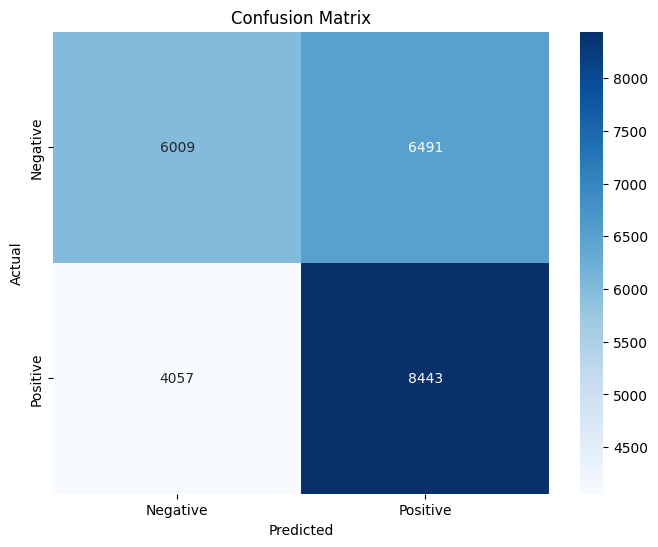

Classification Report:
              precision    recall  f1-score   support

    Negative       0.60      0.48      0.53     12500
    Positive       0.57      0.68      0.62     12500

    accuracy                           0.58     25000
   macro avg       0.58      0.58      0.57     25000
weighted avg       0.58      0.58      0.57     25000



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

vocab_size = 10000
max_length = 50
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

x_train = pad_sequences(x_train, maxlen=max_length)
x_test = pad_sequences(x_test, maxlen=max_length)

glove_file = '/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt'
embedding_dim = 100

embeddings_index = {}
with open(glove_file, 'r', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

embedding_matrix = np.zeros((vocab_size, embedding_dim))
word_index = imdb.get_word_index()
for word, i in word_index.items():
    if i < vocab_size:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(vocab_size, embedding_dim, input_length=max_length, weights=[embedding_matrix], trainable=False))
model.add(Flatten())
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5, batch_size=64, validation_data=(x_test, y_test))

loss, accuracy = model.evaluate(x_test, y_test)
print(f"Final Loss: {loss:.4f}, Final Accuracy: {accuracy:.4f}")

y_pred = (model.predict(x_test) > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred)
precision = cm[1, 1] / (cm[1, 1] + cm[0, 1])
recall = cm[1, 1] / (cm[1, 1] + cm[1, 0])

print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


#Persian Dataset

In [3]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense
from sklearn.metrics import confusion_matrix, precision_score, recall_score
import numpy as np

embedding_dim = 100

persian_dataset = load_dataset("SeyedAli/Persian-Text-Sentiment")

glove_embeddings_index = {}
with open('/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        glove_embeddings_index[word] = coefs

tokenizer = Tokenizer()
tokenizer.fit_on_texts(persian_dataset['train']['text'])
sequences = tokenizer.texts_to_sequences(persian_dataset['train']['text'])

maxlen = 100
X = pad_sequences(sequences, maxlen=maxlen)
y = np.array(persian_dataset['train']['label'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

word_index = tokenizer.word_index
embedding_matrix = np.zeros((len(word_index) + 1, embedding_dim))
for word, i in word_index.items():
    embedding_vector = glove_embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(len(word_index) + 1, embedding_dim, weights=[embedding_matrix], input_length=maxlen, trainable=False))
model.add(Flatten())
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

test_loss, test_accuracy = model.evaluate(X_test, y_test)
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("Precision:", precision)
print("Recall:", recall)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Generating train split:   0%|          | 0/55852 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/13964 [00:00<?, ? examples/s]

Epoch 1/5
1397/1397 [==============================] - 8s 4ms/step - loss: 0.6927 - accuracy: 0.5381 - val_loss: 0.6911 - val_accuracy: 0.5363
Epoch 2/5
1397/1397 [==============================] - 5s 4ms/step - loss: 0.6895 - accuracy: 0.5425 - val_loss: 0.6922 - val_accuracy: 0.5342
Epoch 3/5
1397/1397 [==============================] - 5s 3ms/step - loss: 0.6885 - accuracy: 0.5443 - val_loss: 0.6941 - val_accuracy: 0.5384
Epoch 4/5
1397/1397 [==============================] - 6s 5ms/step - loss: 0.6880 - accuracy: 0.5486 - val_loss: 0.6914 - val_accuracy: 0.5412
Epoch 5/5
350/350 [==============================] - 1s 2ms/step
Confusion Matrix:
[[1724 3925]
 [1234 4288]]
Precision: 0.5220991111652259
Recall: 0.7765302426657008
Test Loss: 0.6936752796173096
Test Accuracy: 0.5381792187690735


In [2]:
!pip install datasets
from datasets import load_dataset

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 10.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.2/401.2 kB 13.4 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface-hub 0.20.3
    Uninstalling huggingface-hub-0.20.3:
      Successfully uninstalled huggingface-hub-0.20.3


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from datasets import load_dataset

persian_dataset = load_dataset("SeyedAli/Persian-Text-Sentiment")

train_texts = [example['text'] for example in persian_dataset['train']]
train_labels = [example['label'] for example in persian_dataset['train']]
test_texts = [example['text'] for example in persian_dataset['test']]
test_labels = [example['label'] for example in persian_dataset['test']]

vocab_size = 50000
max_length = 10000
embedding_dim = 100

train_labels = np.array(train_labels)
test_labels = np.array(test_labels)

tokenizer = Tokenizer(num_words=vocab_size, oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)

train_sequences = tokenizer.texts_to_sequences(train_texts)
test_sequences = tokenizer.texts_to_sequences(test_texts)

train_data = pad_sequences(train_sequences, maxlen=max_length, padding='post', truncating='post')
test_data = pad_sequences(test_sequences, maxlen=max_length, padding='post', truncating='post')

glove_file = '/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt'

embedding_index = {}
with open(glove_file, encoding='utf8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefficients = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coefficients

embedding_matrix = np.zeros((vocab_size, embedding_dim))
word_index = tokenizer.word_index
for word, i in word_index.items():
    if i >= vocab_size:
        continue
    embedding_vector = embedding_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

def evaluate_model(model, test_data, test_labels):
    predictions = model.predict(test_data)
    predictions_binary = [1 if p > 0.5 else 0 for p in predictions]

    accuracy = accuracy_score(test_labels, predictions_binary)
    precision = precision_score(test_labels, predictions_binary)
    recall = recall_score(test_labels, predictions_binary)
    f1 = f1_score(test_labels, predictions_binary)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    cm = confusion_matrix(test_labels, predictions_binary)
    print("Confusion Matrix:")
    print(cm)

top_words = 10
for i in range(1, top_words + 1):
    word = list(word_index.keys())[i]
    word_vector = embedding_matrix[i]

    print("Word:", word)
    print("Word Vector:", word_vector)
    print()

model = Sequential()
model.add(Embedding(vocab_size, embedding_dim, input_length=max_length))
model.add(Flatten())
model.add(Dense(1, activation='sigmoid'))

model.layers[0].set_weights([embedding_matrix])
model.layers[0].trainable = False

print("Model Summary:")
model.summary()

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(train_data, train_labels, epochs=10, batch_size=64, validation_data=(test_data, test_labels))

Word: و
Word Vector: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]

Word: بود
Word Vector: [-0.22050001  0.80101001  0.61671001 -0.048519   -1.01400006 -0.045002
 -0.010709   -0.46032     0.75533998 -0.27627999  0.59220999 -0.17103
  0.35556     0.58938003 -0.27787     0.63033998 -0.46588999 -0.096167
  0.46197     0.33232999 -0.41079     0.38901001 -0.47652    -0.25321001
 -0.2455      0.21897     0.23902    -0.025424   -0.15588    -0.16153
 -0.35214001 -0.44848999 -0.22032    -0.94384998  0.093655    0.021681
 -0.064036   -0.43908    -0.098522   -0.046255    0.33766001  0.2095
 -0.045866    0.11753     0.60255998 -0.63757002 -0.60658997  0.13026001
 -0.25948     0.71372998 -0.11141     0.85763001  0.060949   -0.65967
 -0.1751399

#Third Dataset

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from datasets import load_dataset
from sklearn.model_selection import train_test_split

dataset = load_dataset("saied/persian_news_dataset", split="train", streaming=True)

docs = []
document_count = 1000
counter = 0
skip_counter = 0

for doc in dataset:
    if len(doc['title']) == 0 or len(doc['category']) == 0:
        skip_counter += 1
        if skip_counter % 10000 == 0:
            print(f'{skip_counter} skipped')
        continue
    docs.append(doc)
    counter += 1
    if counter == document_count:
        break

texts = [doc['text'] for doc in docs]
categories = [doc['category'] for doc in docs]

max_words = 10000
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

input_length = 50
X = pad_sequences(sequences, maxlen=input_length)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(categories)
number_of_classes = len(label_encoder.classes_)
y = tf.keras.utils.to_categorical(y, num_classes=number_of_classes)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

glove_embeddings_index = {}
with open('/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        glove_embeddings_index[word] = coefs

embedding_dim = 100
word_index = tokenizer.word_index
num_words = min(max_words, len(word_index) + 1)
embedding_matrix = np.zeros((num_words, embedding_dim))
for word, i in word_index.items():
    if i >= max_words:
        continue
    embedding_vector = glove_embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(input_dim=num_words, output_dim=embedding_dim, input_length=input_length))
model.add(Flatten())
model.add(Dense(6, activation='softmax'))

model.layers[0].set_weights([embedding_matrix])
model.layers[0].trainable = False

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_val, y_val), verbose=2)

val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
y_pred = np.argmax(model.predict(X_val), axis=1)
y_true = np.argmax(y_val, axis=1)

precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')
cm = confusion_matrix(y_true, y_pred)

print(f"Validation Loss: {val_loss}")
print(f"Validation Accuracy: {val_accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print("Confusion Matrix:")
print(cm)

/usr/local/lib/python3.10/dist-packages/datasets/load.py:1486: FutureWarning: The repository for saied/persian_news_dataset contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/saied/persian_news_dataset
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this dataset from the next major release of `datasets`.
  warnings.warn(


10000 skipped
20000 skipped
30000 skipped
40000 skipped
50000 skipped
60000 skipped
70000 skipped
80000 skipped
90000 skipped
100000 skipped
110000 skipped
120000 skipped
130000 skipped
140000 skipped
150000 skipped
160000 skipped
170000 skipped
180000 skipped
190000 skipped
200000 skipped
210000 skipped
Epoch 1/5
25/25 - 1s - loss: 1.5779 - accuracy: 0.3575 - val_loss: 1.5447 - val_accuracy: 0.4300 - 884ms/epoch - 35ms/step
Epoch 2/5
25/25 - 0s - loss: 1.2105 - accuracy: 0.5675 - val_loss: 1.4416 - val_accuracy: 0.4650 - 83ms/epoch - 3ms/step
Epoch 3/5
25/25 - 0s - loss: 1.0434 - accuracy: 0.6175 - val_loss: 1.4322 - val_accuracy: 0.4600 - 84ms/epoch - 3ms/step
Epoch 4/5
25/25 - 0s - loss: 0.9427 - accuracy: 0.6587 - val_loss: 1.4255 - val_accuracy: 0.4450 - 83ms/epoch - 3ms/step
Epoch 5/5
25/25 - 0s - loss: 0.8629 - accuracy: 0.7113 - val_loss: 1.4452 - val_accuracy: 0.4450 - 93ms/epoch - 4ms/step
7/7 [==============================] - 0s 2ms/step
Validation Loss: 1.4451957941055298
